In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import pandas as pd
import numpy as np

score_path = '/home/ywang1/workspace/IntentRewriter/src/evaluation/output/all_scores.jsonl'
with open(score_path, 'r') as f:
    scores = json.load(f)

fluent_our_human = scores['fluent_our_human']
fluent_our_gpt = scores['fluent_our_gpt']
fluent_our_llama = scores['fluent_our_llama']
fluent_sota_human = scores['fluent_sota_human']
fluent_sota_gpt = scores['fluent_sota_gpt']
fluent_sota_llama = scores['fluent_sota_llama']

factual_our_human = scores['factual_our_human']
factual_our_gpt = scores['factual_our_gpt']
factual_our_llama = scores['factual_our_llama']
factual_sota_human = scores['factual_sota_human']
factual_sota_gpt = scores['factual_sota_gpt']
factual_sota_llama = scores['factual_sota_llama']

inclusion_our_human = scores['inclusion_our_human']
inclusion_our_gpt = scores['inclusion_our_gpt']
inclusion_our_llama = scores['inclusion_our_llama']
inclusion_sota_human = scores['inclusion_sota_human']
inclusion_sota_gpt = scores['inclusion_sota_gpt']
inclusion_sota_llama = scores['inclusion_sota_llama']

exclusion_our_human = scores['exclusion_our_human']
exclusion_our_gpt = scores['exclusion_our_gpt']
exclusion_our_llama = scores['exclusion_our_llama']
exclusion_sota_human = scores['exclusion_sota_human']
exclusion_sota_gpt = scores['exclusion_sota_gpt']
exclusion_sota_llama = scores['exclusion_sota_llama']


/scratch-local/69249/ipykernel_1814850/375120486.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), font=times_new_roman_bold, fontweight='bold')  # 首先设置所有标签以确保都被访问
/scratch-local/69249/ipykernel_1814850/375120486.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), font=times_new_roman_bold, fontweight='bold')
/scratch-local/69249/ipykernel_1814850/375120486.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), font=times_new_roman_bold, fontweight='bold')  # 首先设置所有标签以确保都被访问
/scratch-local/69249/ipykernel_1814850/375120486.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. af

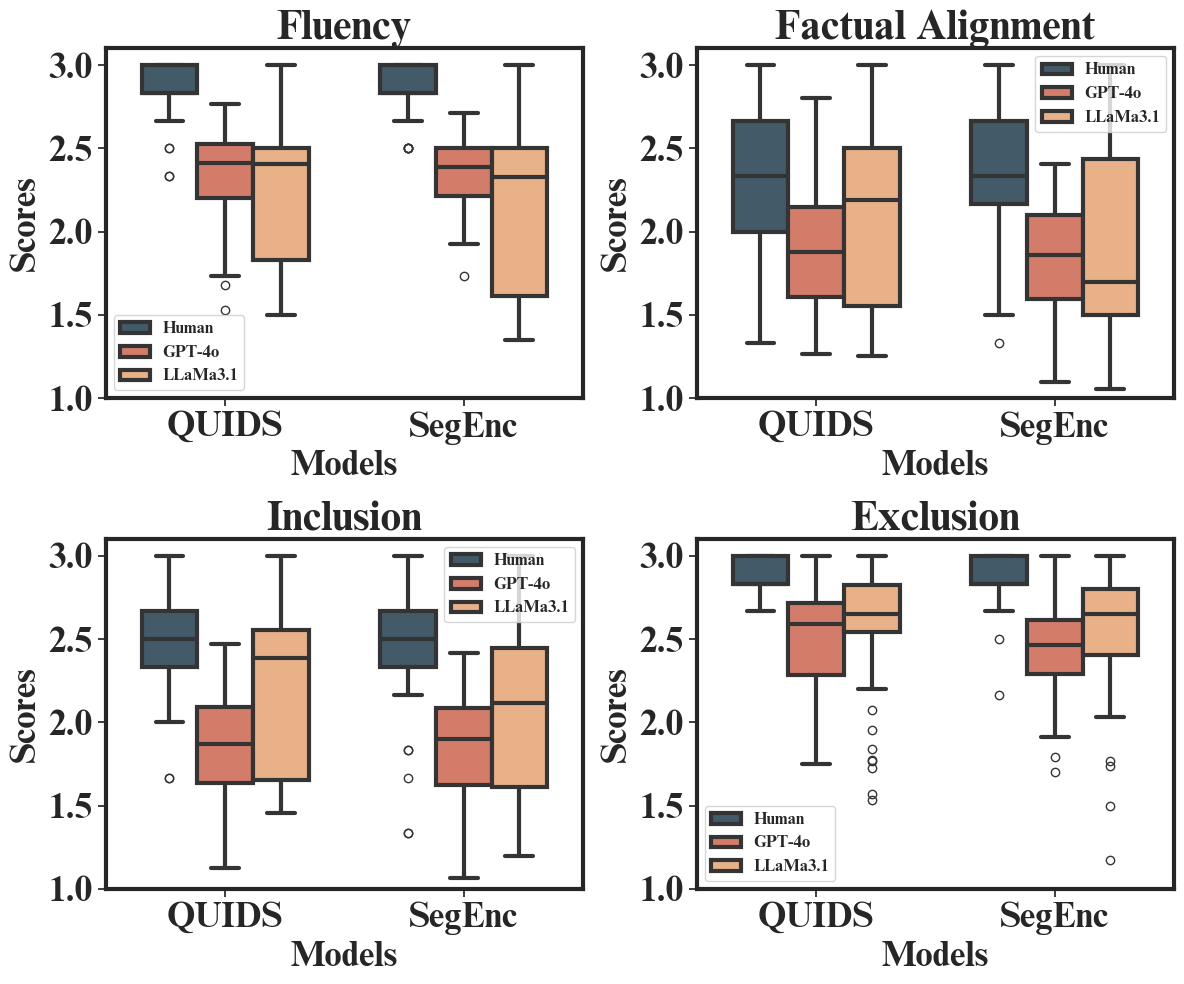

In [8]:

# set font:
import matplotlib.font_manager as fm
font_path = '/home/ywang1/data1/font/times new roman.ttf'
font_bold_path = '/home/ywang1/data1/font/times new roman bold.ttf'
times_new_roman = fm.FontProperties(fname=font_path)
times_new_roman_bold = fm.FontProperties(fname=font_bold_path)

# matplotlib.rcParams.update({
#     # "font.family": 'Times New Roman',
#     "font.family": times_new_roman.get_name(),
#     "font.size": 25,
#     })
# plt.rcParams['font.family'] = times_new_roman.get_name()
# plt.rcParams['font.size'] = 25
# plt.rcParams['font.weight'] = 'bold'

metrics = ['Fluency', 'Factual Alignment', 'Inclusion', 'Exclusion']
models = ['our', 'sota']
methods = ['human', 'gpt', 'llama']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
# custom_palette = sns.color_palette(["#EDC6B1", "#B7B7B7",  "#BFCCB5"])#"#7C96AB",
custom_palette = sns.color_palette(["#3D5C6F", "#E47159", "#F9AE78"])
# custom_palette = sns.color_palette(["#"])
size = len(fluent_our_human)

for i, ax in enumerate(axes.flat):
    m = metrics[i] # start with fluency
    if m == "Fluency":
        metric = "fluent"
    elif m == "Factual Alignment":
        metric = "factual"
    elif m == "Inclusion":
        metric = "inclusion"
    elif m == "Exclusion":
        metric = "exclusion"
    # print(f'{metric}_our_human')
    # data preparation
    data = {'model': ['QUIDS'] * size * 3 + ['SegEnc'] * size * 3,
            'score': scores[f'{metric}_our_human'] + scores[f'{metric}_our_gpt'] + scores[f'{metric}_our_llama'] + \
                        scores[f'{metric}_sota_human'] + scores[f'{metric}_sota_gpt'] + scores[f'{metric}_sota_llama'],
            'method': ['Human'] * size + ['GPT-4o'] * size + ['LLaMa3.1'] * size + \
                        ['Human'] * size + ['GPT-4o'] * size + ['LLaMa3.1'] * size}
    df = pd.DataFrame(data)
    sns.boxplot(x='model', y='score', hue='method', data=df, ax=ax, palette=custom_palette, linewidth=3, width=0.7)
    ax.set_ylim(1, 5.2)
    sns.set(style="ticks", font=times_new_roman.get_name())
    ax.set_xticklabels(ax.get_xticklabels(), font=times_new_roman_bold, fontweight='bold')  # 首先设置所有标签以确保都被访问
    ax.set_yticklabels(ax.get_yticklabels(), font=times_new_roman_bold, fontweight='bold')
    ax.set_xlabel('Models', font=times_new_roman_bold, fontweight='bold', fontsize=25)
    ax.set_ylabel('Scores', font=times_new_roman_bold, fontweight='bold', fontsize=25)

    # 增大轴刻度的字体大小
    ax.tick_params(axis='both', labelsize=25) # 对ax1的x轴和y轴刻度标签字体大小进行调整
    for label in ax.get_xticklabels():
        label.set_fontweight('bold')
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')
    ax.set_title(m, font=times_new_roman_bold, fontweight='bold', fontsize=30)
    # matplotlib.rcParams.update({
    #     "font.family": 'Times New Roman',
    #     "font.size": 25,
    # })
    # 设置legend
    legend = ax.get_legend()
    # legend.set_title('Evaluator', prop=times_new_roman)
    legend.set_title(None)
    # 设置边线宽度
    for spine in ax.spines.values():
        spine.set_linewidth(3)  # Set the spine line width to 2

    for text in legend.get_texts():
        text.set_fontproperties(times_new_roman_bold)
        text.set_fontweight('bold')

plt.tight_layout()
plt.savefig("boxplot_evaluation.pdf")

plt.show()

    


# Calibri font

/scratch-local/69249/ipykernel_1305419/2617022985.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), font=calibri_bold, fontweight='bold')  # 首先设置所有标签以确保都被访问
/scratch-local/69249/ipykernel_1305419/2617022985.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), font=calibri_bold, fontweight='bold')  # 首先设置所有标签以确保都被访问
/scratch-local/69249/ipykernel_1305419/2617022985.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), font=calibri_bold, fontweight='bold')  # 首先设置所有标签以确保都被访问
/scratch-local/69249/ipykernel_1305419/2617022985.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. aft

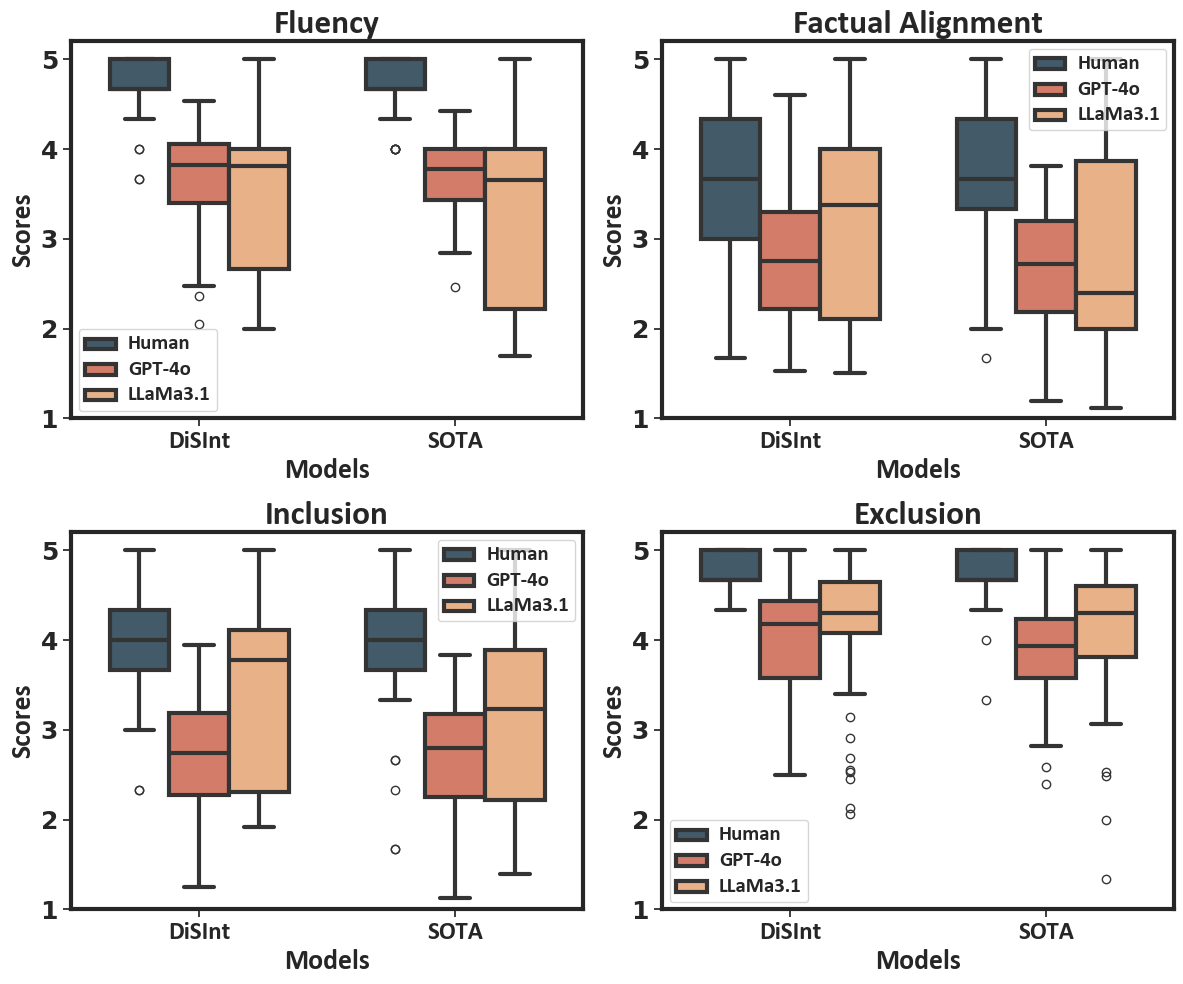

In [25]:

# set font:
import matplotlib.font_manager as fm
font_path = '/home/ywang1/data1/font/Calibri.ttf'
font_bold_path = '/home/ywang1/data1/font/calibrib.ttf'
calibri = fm.FontProperties(fname=font_path)
calibri_bold = fm.FontProperties(fname=font_bold_path)

# matplotlib.rcParams.update({
#     # "font.family": 'Times New Roman',
#     "font.family": times_new_roman.get_name(),
#     "font.size": 25,
#     })
# plt.rcParams['font.family'] = times_new_roman.get_name()
# plt.rcParams['font.size'] = 25
# plt.rcParams['font.weight'] = 'bold'

metrics = ['Fluency', 'Factual Alignment', 'Inclusion', 'Exclusion']
models = ['our', 'sota']
methods = ['human', 'gpt', 'llama']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
# custom_palette = sns.color_palette(["#EDC6B1", "#B7B7B7",  "#BFCCB5"])#"#7C96AB",
custom_palette = sns.color_palette(["#3D5C6F", "#E47159", "#F9AE78"])
# custom_palette = sns.color_palette(["#33395B", "#5D74A2", "#C4D8F2"]) # #33395B, #8E2D30
size = len(fluent_our_human)

for i, ax in enumerate(axes.flat):
    m = metrics[i] # start with fluency
    if m == "Fluency":
        metric = "fluent"
    elif m == "Factual Alignment":
        metric = "factual"
    elif m == "Inclusion":
        metric = "inclusion"
    elif m == "Exclusion":
        metric = "exclusion"
    # print(f'{metric}_our_human')
    # data preparation
    data = {'model': ['DiSInt'] * size * 3 + ['SOTA'] * size * 3,
            'score': scores[f'{metric}_our_human'] + scores[f'{metric}_our_gpt'] + scores[f'{metric}_our_llama'] + \
                        scores[f'{metric}_sota_human'] + scores[f'{metric}_sota_gpt'] + scores[f'{metric}_sota_llama'],
            'method': ['Human'] * size + ['GPT-4o'] * size + ['LLaMa3.1'] * size + \
                        ['Human'] * size + ['GPT-4o'] * size + ['LLaMa3.1'] * size}
    df = pd.DataFrame(data)
    sns.boxplot(x='model', y='score', hue='method', data=df, ax=ax, palette=custom_palette, linewidth=3, width=0.7)
    ax.set_ylim(1, 5.2)
    sns.set(style="ticks", font=calibri.get_name())
    # matplotlib.rcParams.update({
    # "font.family": 'Times New Roman',
    # # "font.family": times_new_roman.get_name(),
    # "font.size": 25,
    # })
    # legend
    # legend = plt.gca().get_legend()
    # for text in legend.get_texts():
    #     text.set_fontweight('bold')
    
    # label
    ax.set_xticklabels(ax.get_xticklabels(), font=calibri_bold, fontweight='bold')  # 首先设置所有标签以确保都被访问
    # ax.set_yticklabels(ax.get_yticklabels(), font=times_new_roman_bold, fontweight='bold')
    ax.set_xlabel('Models', font=calibri_bold, fontweight='bold', fontsize=20)
    ax.set_ylabel('Scores', font=calibri_bold, fontweight='bold', fontsize=20)

    # 增大轴刻度的字体大小
    ax.tick_params(axis='both', labelsize=18) # 对ax1的x轴和y轴刻度标签字体大小进行调整
    for label in ax.get_xticklabels():
        label.set_fontweight('bold')
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')
    ax.set_title(m, font=calibri_bold, fontweight='bold', fontsize=24)
    # matplotlib.rcParams.update({
    #     "font.family": 'Times New Roman',
    #     "font.size": 25,
    # })
    # 设置legend
    legend = ax.get_legend()    
    # legend.set_title('Evaluator', prop=times_new_roman)
    legend.set_title(None)
    # 设置边线宽度
    for spine in ax.spines.values():
        spine.set_linewidth(3)  # Set the spine line width to 2

    for text in legend.get_texts():
        text.set_fontproperties(calibri_bold)
        text.set_fontweight('bold')
        text.set_fontsize(15)

plt.tight_layout()
plt.savefig("boxplot_evaluation.pdf")

plt.show()

    
